In [42]:
#cmd+shift+p to create a notebook
import pandas as pd
import matplotlib.pyplot as plt

In [43]:
import sys
sys.path.append("..")

import pandas as pd
from src.alm import *
# from src.alm import delta_nii_curve

import importlib
import src.alm as alm

importlib.reload(alm)

bs = alm.load_balance_sheet()
yields = alm.load_yields()

cols = ["2yr", "3yr", "5yr", "7yr", "10yr"]
yields = pd.read_csv("../data/yields.csv", index_col="date", parse_dates=True)

Reading file: /Users/bimansaha/Projects/bank-rate-risk-model/model/balance_sheet.csv


In [44]:
print(bs[["line", "balance", "duration"]])

                                  line  balance  duration
0            Fixed-rate 5-yr mortgages       39      3.00
1       Floating-rate commercial loans       23      0.25
2   Fixed-rate government bonds (7-yr)       38      5.00
3        Chequing and savings deposits       55      2.50
4  Term deposits and GICs (1 to 5 yrs)       35      1.50
5        Short-term Wholesale Fundings        2      0.25


In [45]:
steep = tilt(KEYS, pivot=5, slope=0.1)
flat = tilt(KEYS, pivot=5, slope=-0.1)
#steep
print(key_rate_exposure(bs))
print(flat)
#print(steep.tolist())                                    
print(round(delta_eve_curve(bs, steep), 4)) 
print(round(delta_eve_curve(bs, flat), 4))

2    -116.00
3      48.25
5     190.00
7       0.00
10      0.00
dtype: float64
2     0.3
3     0.2
5     0.0
7    -0.2
10   -0.5
dtype: float64
-0.2515
0.2515


In [46]:
cols = ["2yr", "3yr", "5yr", "7yr", "10yr"]

spread = yields["10yr"] - yields["2yr"]
chg = spread.diff(250)          # spread now minus spread 250 business days ago

end_steep = chg.idxmax()        # window that ends with the biggest widening
end_flat = chg.idxmin()         # window that ends with the biggest narrowing

def window_start(end):
    i = yields.index.get_loc(end)
    return yields.index[i - 250]

for name, end in [("steepening", end_steep), ("flattening", end_flat)]:
    start = window_start(end)
    print(name, start.date(), "to", end.date(), "| spread change (pp):", round(chg[end], 2))
    print(historical_shock(yields, start, end).round(2).to_dict())

steepening 2024-06-25 to 2025-06-26 | spread change (pp): 1.31
{2: -1.35, 3: -1.18, 5: -0.54, 7: -0.32, 10: -0.04}
flattening 2021-11-23 to 2022-11-24 | spread change (pp): -1.73
{2: 2.84, 3: 2.47, 5: 1.58, 7: 1.27, 10: 1.11}


In [47]:
shocks = {
    "Parallel +100 bps": pd.Series(1.0, index=KEYS),
    "Parallel -100 bps": pd.Series(-1.0, index=KEYS),
    "Test steepener": tilt(KEYS, pivot=5, slope=0.1),
    "Test flattener": tilt(KEYS, pivot=5, slope=-0.1),
    "Steepener (calibrated)": tilt(KEYS, pivot=5, slope=chg[end_steep] / 8),       # tilt with slope chg[end_steep] / 8
    "Flattener (calibrated)": tilt(KEYS, pivot=5, slope=chg[end_flat] / 8),       # tilt with slope chg[end_flat] / 8
    "Historical steepening": historical_shock(yields, window_start(end_steep), end_steep),
    "Historical flattening": historical_shock(yields, window_start(end_flat), end_flat),        # same, using end_flat
}

eq = equity(bs)
rows = []
for name, s in shocks.items():
    d = delta_eve_curve(bs, s)
    rows.append({"scenario": name, "delta_eve": d, "eve_pct_equity": d / eq * 100, 
                 "delta_nii": delta_nii_curve(bs, s)})

table = pd.DataFrame(rows).set_index("scenario")
table.round(4)

,delta_eve,eve_pct_equity,delta_nii
scenario,,,
Parallel +100 bps,-1.2225,-15.2812,0.0835
Parallel -100 bps,1.2225,15.2812,-0.0835
Test steepener,-0.2515,-3.1438,0.0248
Test flattener,0.2515,3.1438,-0.0248
Steepener (calibrated),-0.4118,-5.1479,0.0406
Flattener (calibrated),0.5439,6.7984,-0.0536
Historical steepening,0.0293,0.3669,0.0091
Historical flattening,-0.8994,-11.2422,0.0623


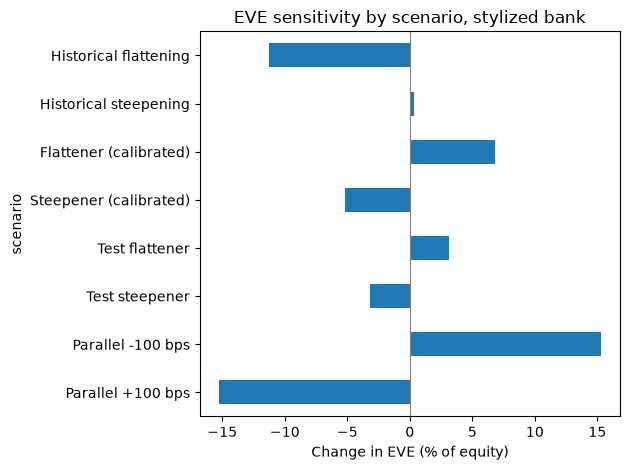

In [48]:
table["eve_pct_equity"].plot.barh()
plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel("Change in EVE (% of equity)")
plt.title("EVE sensitivity by scenario, stylized bank")
plt.tight_layout()
plt.show()

In [49]:
bs[["line", "side"]]
bs["reprice_key"] = [5, 2, 7, 2, 3, 2]
bs.to_csv("../model/balance_sheet.csv", index=False)
bs

,line,side,balance,type,rate,reprice_share,duration,beta,reprice_key
0,Fixed-rate 5-yr mortgages,Asset,39,Fixed,4.38,20,3.00,NaN,5
1,Floating-rate commercial loans,Asset,23,Floating,4.86,100,0.25,NaN,2
2,Fixed-rate government bonds (7-yr),Asset,38,Fixed,3.67,20,5.00,NaN,7
3,Chequing and savings deposits,Liability,55,Non-maturity,0.80,100,2.50,0.3,2
4,Term deposits and GICs (1 to 5 yrs),Liability,35,Fixed,3.06,33,1.50,1.0,3
5,Short-term Wholesale Fundings,Liability,2,Floating,3.61,100,0.25,1.0,2


In [50]:
pd.read_csv("../model/balance_sheet.csv").shape

(6, 9)

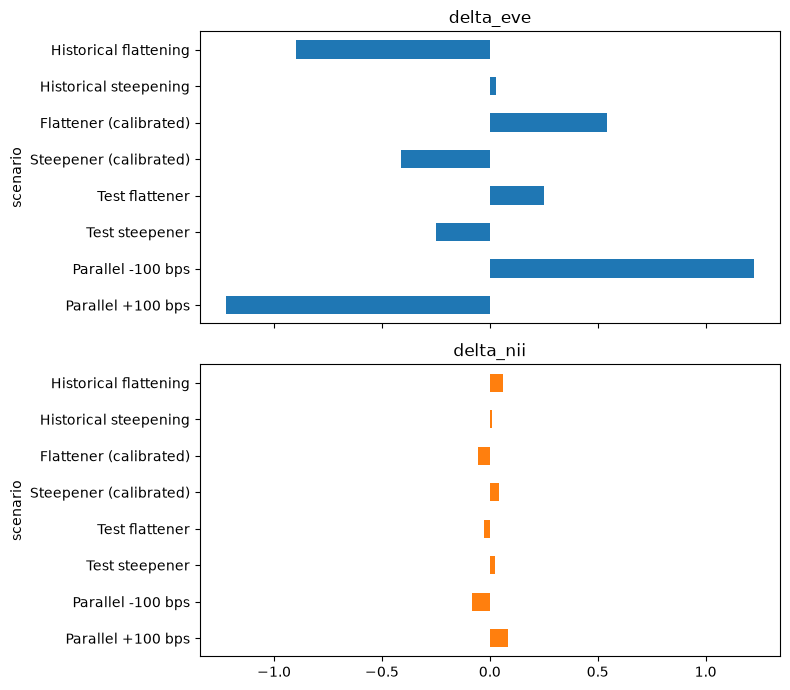

In [51]:
for name, s in shocks.items():
    d = delta_eve_curve(bs, s)
    rows.append({"scenario": name,
                 "delta_eve": d,
                 "eve_pct_equity": d / eq * 100,
                 "delta_nii": delta_nii_curve(bs, s)})
    
table[["delta_eve", "delta_nii"]].plot.barh(subplots=True, legend=False, figsize=(8, 7))
plt.tight_layout()
plt.show()